# Replication of Klein and Chow (2013)

Klein, R. F. and Chow, V. K. (2013), *Orthogonalized factors and systematic risk decomposition*, The Quarterly Review of Economics and Finance 53, 175–187, [doi:10.1016/j.qref.2013.02.003](https://doi.org/10.1016/j.qref.2013.02.003).

Factors such as the market, size, value, momentum and reversal are correlated with each other, so the systematic variance of a portfolio, $\beta' \Sigma \beta$, has cross terms and cannot be split by factor. The paper transforms the factors into uncorrelated versions that stay as close as possible to the originals, and then the systematic variance splits exactly into one term per factor.

This notebook repeats the empirical part of the paper with the current data of the Ken French library, before the method is applied to Brazil in the next notebooks: the same five factors (RM, SMB, HML, Mom and Rev), the same sample (January 1931 to December 2008, 936 months) and the same test portfolios. Each table is shown next to the published numbers. The Monte Carlo of Table 2 and the GMM tests of Table 8 are not repeated.

## The method

Let $F$ be the $T \times K$ matrix of factor returns, $\tilde F$ the demeaned factors and $\Sigma$ their sample covariance matrix, with eigenvalues $D$ and eigenvectors $O$. The Schweinler-Wigner / Löwdin (SW/L) transformation is

$$S = O D^{-1/2} O' \cdot \sqrt{T-1} \cdot \mathrm{diag}(\sigma_1, \dots, \sigma_K) = \Sigma^{-1/2}\,\mathrm{diag}(\sigma), \qquad F^\perp = F S .$$

- The columns of $F^\perp$ are uncorrelated and keep the variances of the original factors.
- It is the symmetric solution of $S S' = \Sigma^{-1}$ (up to scale): no factor is kept unchanged as a leader, so the result does not depend on the order of the factors, unlike Gram-Schmidt.
- $F = F^\perp \Psi$ with $\Psi = S^{-1}$, so a regression on $F^\perp$ has the same intercept, residuals and $R^2$ as a regression on $F$, with betas $\beta^\perp = \Psi \beta$. The diagonal of $\Psi$ is the correlation between each factor and its orthogonal version, the *resemblance*.
- Because the orthogonal factors are uncorrelated, the systematic variance of asset $j$ is $\sigma^2_{s,j} = \sum_k (\beta^\perp_{k,j} \sigma_k)^2$, and the decomposed $R^2$ of factor $k$ is

$$DR^2_{j,k} = \left(\frac{\beta^\perp_{k,j}\,\sigma_k}{\sigma_j}\right)^2, \qquad \sum_k DR^2_{j,k} = R^2_j .$$

The functions are in the `orthofactors` package of this repository.

In [1]:
# Library imports

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
from pathlib import Path

from orthofactors.data import read_ken_french, VALUE_WEIGHTED, EQUAL_WEIGHTED
from orthofactors.orthogonalization import orthogonalize_swl, orthogonalize_pca, orthogonalize_gs, calculate_frobenius_norm
from orthofactors.decomposition import run_ols, decompose, variance_levels, rolling_window_regression
from orthofactors.plotting import set_style, plot_decomposition, DIVERGING

set_style()
Path('results').mkdir(exist_ok = True)

## Data

The files are downloaded from the [Ken French data library](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library.html) the first time the notebook runs and kept in `data/external/`, which git ignores. All returns are monthly and in decimals; the tables below show percent, as the paper does.

In [2]:
# Factors of the paper: market excess return, size, value, momentum and long-term reversal
ff3 = read_ken_french('F-F_Research_Data_Factors')
factors = pd.concat([ff3[['Mkt-RF', 'SMB', 'HML']],
                     read_ken_french('F-F_Momentum_Factor')['Mom'],
                     read_ken_french('F-F_LT_Reversal_Factor')['LT_Rev']], axis = 1)
factors.columns = ['RM', 'SMB', 'HML', 'Mom', 'Rev']
risk_free = ff3['RF']
paper_factors = factors.columns.tolist()

# Sample of the paper: January 1931 to December 2008
sample = slice('1931-01', '2008-12')
F = factors.loc[sample]
print(f'{len(F)} months, from {F.index[0]:%Y-%m} to {F.index[-1]:%Y-%m}; data available to {factors.dropna().index[-1]:%Y-%m}')

936 months, from 1931-01 to 2008-12; data available to 2026-09


In [3]:
# Test portfolios in excess of the T-bill: the 18 style portfolios (6 on size and book-to-market, 6 on size and
# momentum, 6 on size and long-term reversal), the 30 industries and the 25 portfolios on size and book-to-market
style_files = {'6_Portfolios_2x3': ('BE/ME', ['Growth', 'Neutral', 'Value']),
               '6_Portfolios_ME_Prior_12_2': ('Momentum', ['Down', 'Medium', 'Up']),
               '6_Portfolios_ME_Prior_60_13': ('Reversal', ['Low', 'Medium', 'High'])}

def style_portfolios(title):
    frames = []
    for file, (sort, groups) in style_files.items():
        table = read_ken_french(file, title).sub(risk_free, axis = 0)
        table.columns = pd.MultiIndex.from_tuples([(size, sort, group) for size in ['Small', 'Big'] for group in groups])
        frames.append(table)
    return pd.concat(frames, axis = 1)

weightings = {'EW': EQUAL_WEIGHTED, 'VW': VALUE_WEIGHTED}
styles = {w: style_portfolios(title) for w, title in weightings.items()}
industries = {w: read_ken_french('30_Industry_Portfolios', title).sub(risk_free, axis = 0) for w, title in weightings.items()}
size_bm_25 = read_ken_french('25_Portfolios_5x5', VALUE_WEIGHTED).sub(risk_free, axis = 0)

In [4]:
# Published values used for the comparisons, typed from the tables of the paper
def parse(text, levels):
    rows = [line.split() for line in text.strip().splitlines()]
    index = pd.MultiIndex.from_tuples([tuple(row[:levels]) for row in rows]) if levels > 1 else [row[0] for row in rows]
    return pd.DataFrame([[float(v) for v in row[levels:]] for row in rows], index = index)

paper_table1 = parse('''
RM&SMB 0.992 0.978 0.986 0.874 1.000 0.941 30.518 57.877 35.994
RM&HML 0.996 0.990 0.987 0.922 1.000 0.970 22.171 51.239 29.428
RM&Mom 0.987 0.982 0.909 0.709 1.000 0.946 38.748 128.797 54.975
RM&Rev 0.995 0.989 0.988 0.920 1.000 0.968 22.824 50.529 28.768
SMB&HML 0.999 0.999 0.869 0.913 1.000 0.994 7.465 70.009 17.464
SMB&Mom 0.996 0.998 0.957 0.990 1.000 0.991 12.920 36.675 30.671
SMB&Rev 0.976 0.979 0.590 0.871 1.000 0.908 31.769 123.197 47.165
HML&Mom 0.972 0.984 0.746 0.952 1.000 0.925 37.327 88.974 63.458
HML&Rev 0.947 0.945 0.904 0.450 1.000 0.787 51.105 116.381 71.404
Mom&Rev 0.994 0.990 0.970 0.882 1.000 0.975 21.661 63.158 28.691
''', 1)

# Table 5: naive sum of (beta sigma)^2 and systematic variance, percent squared
paper_table5 = parse('''
EW Small_Growth 50.993 69.060
EW Small_Value 50.982 84.527
EW Small_Down_Mom 56.734 97.544
EW Small_Low_Rev 55.659 97.899
EW Big_Growth 34.086 35.364
EW Big_Value 46.020 61.546
EW Big_Down_Mom 47.475 65.914
EW Big_Low_Rev 42.947 58.829
VW Small_Growth 47.934 60.757
VW Small_Value 47.011 69.520
VW Small_Down_Mom 52.649 84.143
VW Small_Low_Rev 49.442 80.699
VW Big_Growth 30.760 27.709
VW Big_Value 43.253 52.456
VW Big_Down_Mom 44.146 56.307
VW Big_Low_Rev 41.966 49.210
''', 2)

# Table 6: decomposed R2 (RM, SMB, HML, Mom, Rev) and 1 - R2, in percent
paper_table6 = parse('''
EW Small BE/ME Growth 57.09 29.80 0.06 4.96 1.68 6.41
EW Small BE/ME Neutral 58.09 25.02 3.82 5.10 4.58 3.40
EW Small BE/ME Value 45.69 24.25 11.03 6.62 8.19 4.23
EW Small Momentum Down 43.52 23.93 4.42 15.82 5.43 6.88
EW Small Momentum Medium 53.39 23.26 7.68 5.34 5.76 4.58
EW Small Momentum Up 59.37 27.14 2.51 0.01 6.17 4.79
EW Small Reversal Low 41.90 27.30 6.83 6.41 10.74 6.82
EW Small Reversal Medium 57.99 19.99 7.48 6.69 4.68 3.18
EW Small Reversal High 62.65 21.41 3.83 7.51 0.28 4.32
EW Big BE/ME Growth 88.10 4.73 0.25 3.59 0.08 3.26
EW Big BE/ME Neutral 80.12 3.20 5.54 5.05 1.94 4.15
EW Big BE/ME Value 65.80 3.46 16.43 7.28 3.89 3.15
EW Big Momentum Down 66.51 3.45 2.89 23.43 1.24 2.49
EW Big Momentum Medium 81.98 3.05 4.14 6.04 1.03 3.76
EW Big Momentum Up 87.08 6.79 0.57 1.68 0.84 3.03
EW Big Reversal Low 67.05 3.88 6.33 5.17 13.71 3.86
EW Big Reversal Medium 80.18 2.73 5.87 4.36 2.77 4.09
EW Big Reversal High 88.44 4.03 0.78 3.38 0.55 2.82
VW Small BE/ME Growth 66.52 26.98 0.06 2.46 1.72 2.26
VW Small BE/ME Neutral 66.86 20.87 3.99 2.74 3.41 2.13
VW Small BE/ME Value 56.91 18.98 12.50 4.78 6.04 0.79
VW Small Momentum Down 55.48 18.63 3.43 17.31 3.23 1.92
VW Small Momentum Medium 63.17 19.02 6.12 4.96 3.58 3.15
VW Small Momentum Up 68.76 23.23 1.38 0.29 3.81 2.54
VW Small Reversal Low 53.67 23.57 6.06 4.59 9.94 2.16
VW Small Reversal Medium 64.45 16.13 6.89 5.67 3.86 3.01
VW Small Reversal High 68.44 19.24 2.89 6.25 0.01 3.18
VW Big BE/ME Growth 95.10 0.44 0.43 1.90 0.04 2.09
VW Big BE/ME Neutral 83.00 0.17 6.04 4.25 1.97 4.56
VW Big BE/ME Value 69.11 1.15 18.15 5.35 3.39 2.85
VW Big Momentum Down 66.42 0.64 2.00 27.44 0.71 2.79
VW Big Momentum Medium 86.78 0.19 2.24 6.53 0.29 3.98
VW Big Momentum Up 92.26 1.32 0.43 2.42 0.10 3.46
VW Big Reversal Low 68.03 1.35 4.64 3.71 18.10 4.17
VW Big Reversal Medium 85.23 0.23 3.62 3.04 2.69 5.19
VW Big Reversal High 93.26 0.84 0.17 1.77 1.21 2.76
''', 4)

# Table 7: decomposed R2 and 1 - R2 of the 30 industries, equal-weighted then value-weighted, in percent
paper_table7 = parse('''
Food 58.46 12.45 5.78 5.11 3.61 14.58 67.56 0.07 1.22 1.53 0.10 29.51
Beer 36.86 15.75 3.21 0.98 2.42 40.78 44.65 4.29 1.63 0.28 1.07 48.08
Smoke 33.76 3.81 1.36 2.39 2.46 56.23 32.88 0.04 0.69 1.22 0.25 64.92
Games 51.26 15.62 2.98 5.61 2.73 21.78 60.47 5.19 1.01 4.04 1.57 27.72
Books 52.68 18.54 2.65 4.58 2.09 19.47 64.85 5.31 1.68 1.91 0.89 25.36
Hshld 57.45 19.65 2.30 3.71 3.84 13.05 66.36 0.22 0.08 0.91 1.43 30.99
Clths 44.65 22.34 5.44 6.77 4.11 16.69 44.66 9.48 0.06 1.73 0.32 43.75
Hlth 57.69 17.53 0.61 1.49 1.14 21.54 64.67 0.16 0.28 0.93 0.22 33.73
Chems 69.16 11.15 3.19 4.13 1.70 10.66 75.38 0.08 0.52 2.19 0.58 21.25
Txtls 47.83 18.14 4.32 5.37 2.98 21.36 55.98 9.82 4.13 4.49 1.88 23.70
Cnstr 55.62 21.03 4.42 4.49 3.54 10.89 77.22 4.14 1.28 1.97 0.67 14.71
Steel 59.94 10.85 7.19 6.47 2.86 12.69 65.43 3.00 3.45 4.22 1.63 22.27
FabPr 64.77 17.55 3.21 4.02 2.69 7.76 75.75 4.23 1.37 3.83 0.92 13.90
ElcEq 63.66 15.84 1.72 3.22 2.27 13.28 77.36 0.50 0.31 2.74 1.29 17.80
Autos 59.08 14.86 4.65 5.81 4.04 11.55 63.32 0.65 2.25 5.26 2.65 25.88
Carry 52.99 12.68 7.21 3.74 1.92 21.46 60.95 3.50 4.83 2.63 0.62 27.47
Mines 35.57 11.98 4.84 2.23 1.79 43.60 40.44 4.32 2.05 1.01 0.12 52.06
Coal 26.62 11.52 8.51 3.04 0.75 49.55 22.13 3.66 1.90 0.00 0.34 71.97
Oil 49.36 6.96 5.54 0.77 0.49 36.87 59.66 0.06 4.41 0.26 0.02 35.59
Util 46.08 2.35 9.00 4.54 5.28 32.75 51.66 0.01 6.59 3.05 1.42 37.27
Telcm 55.72 10.63 0.84 4.15 0.78 27.88 55.38 0.00 0.07 3.70 0.43 40.42
Servs 39.49 24.60 0.36 1.68 0.99 32.88 29.23 4.53 3.16 0.14 0.01 62.93
BusEq 59.54 19.89 0.47 2.73 1.68 15.70 70.49 2.61 4.56 1.18 0.41 20.75
Paper 53.88 18.38 3.49 4.93 2.51 16.82 71.15 0.49 0.91 2.48 0.24 24.72
Trans 45.72 16.94 12.12 7.41 3.98 13.83 63.30 3.35 8.74 5.42 0.54 18.64
Whlsl 40.20 29.64 1.55 2.52 3.97 22.11 58.90 11.13 0.61 0.90 1.11 27.35
Rtail 56.43 18.29 1.44 5.73 2.53 15.58 69.42 1.68 0.01 3.11 0.32 25.45
Meals 44.20 18.99 1.32 2.09 0.67 32.73 54.04 5.93 0.46 1.24 0.05 38.29
Fin 56.98 11.13 8.68 7.24 4.17 11.79 75.16 0.61 3.55 6.13 0.84 13.69
Other 49.34 22.70 1.31 3.13 3.14 20.38 65.77 5.58 0.13 1.35 0.83 26.33
''', 1)

# Each row of the decomposition tables adds up to 100%, which checks the typing
assert (paper_table6.sum(axis = 1) - 100).abs().max() < 0.05
assert (paper_table7.iloc[:, :6].sum(axis = 1) - 100).abs().max() < 0.05
assert (paper_table7.iloc[:, 6:].sum(axis = 1) - 100).abs().max() < 0.05

## Table 3: the factors before and after the transformation

In [5]:
# SW/L transformation over the full sample, with S and Psi = S^-1
F_ortho, S, Psi = orthogonalize_swl(F, return_matrices = True)

pd.Series({'Largest correlation between two orthogonal factors': (F_ortho.corr() - np.eye(len(paper_factors))).abs().max().max(),
           'Largest relative change of a standard deviation': (F_ortho.std() / F.std() - 1).abs().max()})

Largest correlation between two orthogonal factors    1.711638e-15
Largest relative change of a standard deviation       5.551115e-16
dtype: float64

In [6]:
# Moments in percent per month, and the resemblance diag(Psi) = corr(f_k, f_k orthogonal)
paper_table3 = pd.DataFrame({'Mean': [0.61, 0.29, 0.44, 0.70, 0.35],
                             'Mean ⊥': [0.67, 0.23, 0.55, 0.99, 0.17],
                             'Std. dev.': [5.40, 3.36, 3.61, 4.71, 3.54],
                             'Skewness': [0.30, 2.29, 1.91, -3.04, 2.95],
                             'Skewness ⊥': [-0.24, 1.44, 0.63, -2.04, 1.97],
                             'Excess kurtosis': [8.34, 22.99, 16.11, 28.33, 24.22],
                             'Excess kurtosis ⊥': [4.82, 14.89, 5.54, 15.45, 17.40],
                             'Resemblance': [0.97, 0.96, 0.92, 0.97, 0.91]}, index = paper_factors)

table3 = pd.DataFrame({'Mean': F.mean() * 100, 'Mean ⊥': F_ortho.mean() * 100, 'Std. dev.': F.std() * 100,
                       'Skewness': F.skew(), 'Skewness ⊥': F_ortho.skew(),
                       'Excess kurtosis': F.kurt(), 'Excess kurtosis ⊥': F_ortho.kurt(),
                       'Resemblance': pd.Series(np.diag(Psi), index = paper_factors)})

pd.concat({'Paper': paper_table3, 'This repository': table3}).round(2)

Mean  Mean ⊥  Std. dev.  Skewness  Skewness ⊥  \
Paper           RM   0.61    0.67       5.40      0.30       -0.24   
                SMB  0.29    0.23       3.36      2.29        1.44   
                HML  0.44    0.55       3.61      1.91        0.63   
                Mom  0.70    0.99       4.71     -3.04       -2.04   
                Rev  0.35    0.17       3.54      2.95        1.97   
This repository RM   0.61    0.68       5.42      0.34       -0.21   
                SMB  0.27    0.20       3.27      1.98        1.20   
                HML  0.47    0.59       3.63      2.42        0.80   
                Mom  0.69    1.00       4.75     -3.23       -2.09   
                Rev  0.37    0.17       3.54      3.12        2.13   

                     Excess kurtosis  Excess kurtosis ⊥  Resemblance  
Paper           RM              8.34               4.82         0.97  
                SMB            22.99              14.89         0.96  
                HML            16.11               5.54         0.92  
                Mom            28.33              15.45         0.97  
                Rev            24.22              17.40         0.91  
This repository RM              8.44               4.78         0.97  
                SMB            19.26              12.26         0.96  
                HML            20.33               5.59         0.91  
                Mom            30.54              15.88         0.96  
                Rev            26.00              19.46         0.91

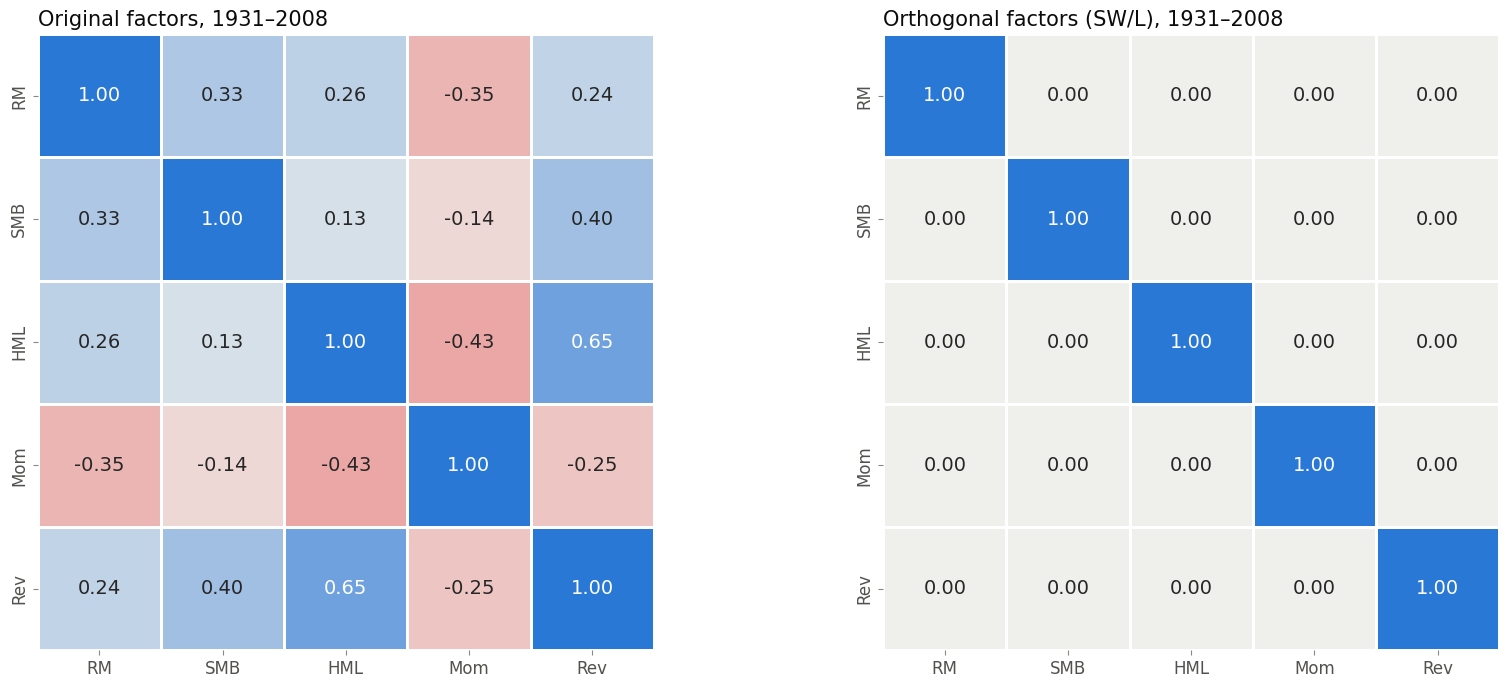

In [7]:
# Correlations of the original and the orthogonal factors (Panel B of Table 3)
fig, axes = plt.subplots(1, 2, figsize = (20, 8))
for ax, data, title in zip(axes, [F, F_ortho], ['Original factors, 1931–2008', 'Orthogonal factors (SW/L), 1931–2008']):
    sns.heatmap(data.corr().round(2) + 0.0, annot = True, fmt = '.2f', cmap = DIVERGING, vmin = -1, vmax = 1, square = True,
                cbar = False, linewidths = 2, linecolor = 'white', annot_kws = {'size': 14}, ax = ax)
    ax.set_title(title)
    ax.grid(False)
plt.show()

The transformation does what the paper describes. The orthogonal factors are uncorrelated, keep the standard deviations and stay close to the originals, with resemblances from 0.91 (HML and Rev) to 0.97 (RM). The premia change: the mean of Mom goes from 0.69% to 1.00% a month and the mean of Rev from 0.37% to 0.17%, against 0.70% to 0.99% and 0.35% to 0.17% in the paper.

The moments differ a little from the paper because the library has revised its data since then: these files were built from the CRSP database of September 2026, as their first line says. The changes are largest for SMB and HML and in the kurtosis, which depends on a few extreme months. HML and Rev are still the most correlated pair, at 0.65 against 0.61.

## Table 1: SW/L against PCA and Gram-Schmidt, for each pair of factors

For each of the ten pairs, the two factors are orthogonalized alone with the three methods. Panel A is the correlation of each original factor with its orthogonal version, in the order of the pair; Gram-Schmidt keeps the first factor of the pair unchanged. Panel B is the Frobenius norm of $F - F^\perp$ in percent. PCA and Gram-Schmidt are rescaled to the original variances.

In [8]:
columns_a = pd.MultiIndex.from_product([['SW/L', 'PCA', 'GS'], ['first', 'second']])
panel_a, panel_b = {}, {}
for a, b in combinations(paper_factors, 2):
    pair = F[[a, b]]
    methods = {'SW/L': orthogonalize_swl(pair), 'PCA': orthogonalize_pca(pair), 'GS': orthogonalize_gs(pair, [a, b])}
    panel_a[f'{a}&{b}'] = [pair[c].corr(methods[m][c]) for m in methods for c in (a, b)]
    panel_b[f'{a}&{b}'] = [calculate_frobenius_norm(pair * 100, methods[m] * 100) for m in methods]

panel_a = pd.DataFrame(panel_a, index = columns_a).T
panel_b = pd.DataFrame(panel_b, index = ['SW/L', 'PCA', 'GS']).T
paper_panel_a = pd.DataFrame(paper_table1.iloc[:, :6].values, index = panel_a.index, columns = columns_a)
paper_panel_b = pd.DataFrame(paper_table1.iloc[:, 6:].values, index = panel_b.index, columns = panel_b.columns)

pd.concat({'Paper': paper_panel_a, 'This repository': panel_a}, axis = 1).round(3)

Paper                                   This repository         \
          SW/L           PCA           GS                   SW/L          
         first second  first second first second           first second   
RM&SMB   0.992  0.978  0.986  0.874   1.0  0.941           0.992  0.978   
RM&HML   0.996  0.990  0.987  0.922   1.0  0.970           0.994  0.988   
RM&Mom   0.987  0.982  0.909  0.709   1.0  0.946           0.986  0.982   
RM&Rev   0.995  0.989  0.988  0.920   1.0  0.968           0.995  0.989   
SMB&HML  0.999  0.999  0.869  0.913   1.0  0.994           0.998  0.998   
SMB&Mom  0.996  0.998  0.957  0.990   1.0  0.991           0.996  0.998   
SMB&Rev  0.976  0.979  0.590  0.871   1.0  0.908           0.978  0.981   
HML&Mom  0.972  0.984  0.746  0.952   1.0  0.925           0.968  0.981   
HML&Rev  0.947  0.945  0.904  0.450   1.0  0.787           0.941  0.938   
Mom&Rev  0.994  0.990  0.970  0.882   1.0  0.975           0.994  0.990   

                                    
           PCA           GS         
         first second first second  
RM&SMB   0.988  0.883   1.0  0.945  
RM&HML   0.985  0.905   1.0  0.966  
RM&Mom   0.905  0.698   1.0  0.936  
RM&Rev   0.988  0.922   1.0  0.971  
SMB&HML  0.866  0.925   1.0  0.991  
SMB&Mom  0.965  0.993   1.0  0.990  
SMB&Rev  0.622  0.882   1.0  0.918  
HML&Mom  0.724  0.952   1.0  0.901  
HML&Rev  0.913  0.434   1.0  0.764  
Mom&Rev  0.971  0.880   1.0  0.968

In [9]:
pd.concat({'Paper': paper_panel_b, 'This repository': panel_b}, axis = 1).round(2)

Paper                This repository               
          SW/L     PCA     GS            SW/L     PCA     GS
RM&SMB   30.52   57.88  35.99           29.55   54.63  33.31
RM&HML   22.17   51.24  29.43           24.78   56.40  29.05
RM&Mom   38.75  128.80  54.98           39.90  133.95  51.96
RM&Rev   22.82   50.53  28.77           22.62   50.06  26.30
SMB&HML   7.46   70.01  17.46            9.91   67.37  14.70
SMB&Mom  12.92   36.67  30.67           12.25   31.98  21.04
SMB&Rev  31.77  123.20  47.16           30.10  101.75  43.97
HML&Mom  37.33   88.97  63.46           40.74   93.90  64.80
HML&Rev  51.10  116.38  71.40           54.25  124.23  74.42
Mom&Rev  21.66   63.16  28.69           22.43   63.51  27.32

In [10]:
# SW/L has the smallest deviation in every pair, in the paper and here
(paper_panel_b['SW/L'] < paper_panel_b[['PCA', 'GS']].min(axis = 1)).all(), (panel_b['SW/L'] < panel_b[['PCA', 'GS']].min(axis = 1)).all()

(np.True_, np.True_)

SW/L keeps both factors of every pair closest to the originals. Its lowest correlation is 0.938 (Rev, in HML & Rev), against 0.434 for PCA and 0.764 for Gram-Schmidt, which keeps the first factor intact at the cost of the second. Its deviation is the smallest in all ten pairs, as in the paper. The SW/L correlations are within 0.01 of the published ones; PCA and Gram-Schmidt move a little more with the data revisions.

## Table 4: betas on the original and on the orthogonal factors

Eight equal-weighted portfolios: four on size and book-to-market, the two down-momentum and the two low-reversal portfolios. OLS t-statistics, as in the paper.

In [11]:
eight = {'Small_Growth': ('Small', 'BE/ME', 'Growth'), 'Small_Value': ('Small', 'BE/ME', 'Value'),
         'Small_Down_Mom': ('Small', 'Momentum', 'Down'), 'Small_Low_Rev': ('Small', 'Reversal', 'Low'),
         'Big_Growth': ('Big', 'BE/ME', 'Growth'), 'Big_Value': ('Big', 'BE/ME', 'Value'),
         'Big_Down_Mom': ('Big', 'Momentum', 'Down'), 'Big_Low_Rev': ('Big', 'Reversal', 'Low')}

betas, tstats = {}, {}
for name, column in eight.items():
    y = styles['EW'][column].loc[sample]
    original, orthogonal = run_ols(y, F), run_ols(y, F_ortho)
    betas[name] = pd.concat([original.params[paper_factors], orthogonal.params[paper_factors]], keys = ['β', 'β⊥'])
    tstats[name] = pd.concat([original.tvalues[paper_factors], orthogonal.tvalues[paper_factors]], keys = ['β', 'β⊥'])
table4 = pd.DataFrame(betas).T

# The orthogonal betas are Psi times the original ones (footnote 19)
assert np.allclose(table4['β⊥'].values, table4['β'].values @ Psi.values.T)
table4.round(3)

β                                 β⊥                       \
                   RM    SMB    HML    Mom    Rev     RM    SMB    HML    Mom   
Small_Growth    1.038  1.259 -0.111 -0.183 -0.062  1.175  1.404  0.069 -0.387   
Small_Value     0.951  1.201  0.759 -0.150  0.160  1.167  1.388  0.911 -0.509   
Small_Down_Mom  0.985  1.310  0.365 -0.574  0.131  1.245  1.512  0.649 -0.856   
Small_Low_Rev   0.982  1.370  0.527 -0.201  0.393  1.222  1.603  0.795 -0.546   
Big_Growth      1.059  0.210 -0.230 -0.095 -0.053  1.049  0.399 -0.069 -0.245   
Big_Value       1.123  0.222  0.775 -0.117  0.021  1.205  0.455  0.880 -0.464   
Big_Down_Mom    1.133  0.217  0.147 -0.631 -0.036  1.239  0.459  0.414 -0.844   
Big_Low_Rev     1.106  0.125  0.212 -0.091  0.607  1.169  0.468  0.553 -0.374   

                       
                  Rev  
Small_Growth    0.276  
Small_Value     0.748  
Small_Down_Mom  0.655  
Small_Low_Rev   0.922  
Big_Growth      0.041  
Big_Value       0.459  
Big_Down_Mom    0.247  
Big_Low_Rev     0.780

In [12]:
pd.DataFrame(tstats).T.round(2)

β                                  β⊥                \
                    RM    SMB    HML    Mom    Rev      RM    SMB    HML   
Small_Growth     69.18  49.21  -3.85 -10.36  -2.12   88.16  63.65   3.46   
Small_Value      71.20  52.75  29.63  -9.56   6.10   98.37  70.72  51.43   
Small_Down_Mom   53.99  42.13  10.42 -26.81   3.66   76.83  56.37  26.83   
Small_Low_Rev    54.00  44.24  15.11  -9.40  11.04   75.72  60.02  33.00   
Big_Growth      143.81  16.77 -16.26 -10.93  -3.70  160.33  36.88  -7.03   
Big_Value       116.52  13.51  41.91 -10.37   1.13  140.80  32.11  68.83   
Big_Down_Mom    128.69  14.43   8.72 -61.03  -2.07  158.42  35.48  35.43   
Big_Low_Rev     110.66   7.36  11.04  -7.77  30.97  131.67  31.83  41.69   

                              
                  Mom    Rev  
Small_Growth   -25.47  13.54  
Small_Value    -37.67  41.22  
Small_Down_Mom -46.35  26.42  
Small_Low_Rev  -29.67  37.35  
Big_Growth     -32.80   4.10  
Big_Value      -47.50  35.09  
Big_Down_Mom   -94.64  20.63  
Big_Low_Rev    -36.96  57.42

In [13]:
# Two cells the paper discusses: the reversal beta of Small Low Rev and the value beta of Small Growth
pd.DataFrame({'Paper': [0.4186, 0.9482, -0.0920, 0.0570],
              'This repository': [table4.loc['Small_Low_Rev', ('β', 'Rev')], table4.loc['Small_Low_Rev', ('β⊥', 'Rev')],
                                  table4.loc['Small_Growth', ('β', 'HML')], table4.loc['Small_Growth', ('β⊥', 'HML')]]},
             index = ['Small Low Rev, β Rev', 'Small Low Rev, β⊥ Rev', 'Small Growth, β HML', 'Small Growth, β⊥ HML']).round(3)

,Paper,This repository
"Small Low Rev, β Rev",0.419,0.393
"Small Low Rev, β⊥ Rev",0.948,0.922
"Small Growth, β HML",-0.092,-0.111
"Small Growth, β⊥ HML",0.057,0.069


As in the paper, the orthogonal betas are usually larger in absolute value, because each original beta is measured net of the overlap with the other factors. The reversal beta of Small Low Rev goes from 0.39 to 0.92 (0.42 to 0.95 in the paper), and the value beta of Small Growth changes sign, from −0.11 to +0.07 (−0.09 to +0.06). The assertion above confirms that the orthogonal betas are Ψ times the original ones.

## Table 5: the systematic variance, factor by factor

The systematic variance is the total variance minus the residual variance. With the orthogonal factors, the terms $(\beta^\perp_k \sigma_k)^2$ add up to it exactly; with the original factors, the terms $(\beta_k \sigma_k)^2$ leave out the covariances. Values in percent squared.

In [14]:
levels = {}
for w in weightings:
    for name, column in eight.items():
        table = variance_levels(styles[w][column].loc[sample], F) * 1e4
        levels[(w, name)] = table
table5 = pd.DataFrame({key: {'Naive sum': t.loc['sum', 'original'], 'Systematic variance': t.loc['systematic', 'original'],
                             'Orthogonal sum': t.loc['sum', 'orthogonal']} for key, t in levels.items()}).T
paper_table5.columns = ['Naive sum', 'Systematic variance']

pd.concat({'Paper': paper_table5, 'This repository': table5}, axis = 1).round(2)

Paper                     This repository  \
                  Naive sum Systematic variance       Naive sum   
EW Small_Growth       50.99               69.06           49.64   
   Small_Value        50.98               84.53           50.44   
   Small_Down_Mom     56.73               97.54           56.32   
   Small_Low_Rev      55.66               97.90           54.93   
   Big_Growth         34.09               35.36           34.37   
   Big_Value          46.02               61.55           45.83   
   Big_Down_Mom       47.48               65.91           47.52   
   Big_Low_Rev        42.95               58.83           41.53   
VW Small_Growth       47.93               60.76           46.96   
   Small_Value        47.01               69.52           46.96   
   Small_Down_Mom     52.65               84.14           52.94   
   Small_Low_Rev      49.44               80.70           49.49   
   Big_Growth         30.76               27.71           31.22   
   Big_Value          43.25               52.46           43.22   
   Big_Down_Mom       44.15               56.31           44.06   
   Big_Low_Rev        41.97               49.21           40.56   

                                                      
                  Systematic variance Orthogonal sum  
EW Small_Growth                 66.11          66.11  
   Small_Value                  84.45          84.45  
   Small_Down_Mom               97.50          97.50  
   Small_Low_Rev                97.15          97.15  
   Big_Growth                   35.44          35.44  
   Big_Value                    62.60          62.60  
   Big_Down_Mom                 66.43          66.43  
   Big_Low_Rev                  57.30          57.30  
VW Small_Growth                 57.87          57.87  
   Small_Value                  70.19          70.19  
   Small_Down_Mom               85.56          85.56  
   Small_Low_Rev                81.74          81.74  
   Big_Growth                   28.12          28.12  
   Big_Value                    52.53          52.53  
   Big_Down_Mom                 56.60          56.60  
   Big_Low_Rev                  47.99          47.99

In [15]:
# Factor by factor for Small Value, equal-weighted
levels[('EW', 'Small_Value')].round(2)

,original,orthogonal
RM,26.57,39.98
SMB,15.46,20.66
HML,7.59,10.93
Mom,0.51,5.86
Rev,0.32,7.02
sum,50.44,84.45
systematic,84.45,84.45
idiosyncratic,3.84,3.84
total,88.29,88.29


With the original factors, the terms add up to much less than the systematic variance: for the equal-weighted Small Value, 50.4 against 84.5. With the orthogonal factors they add up to it exactly. The one portfolio where the naive sum is larger, the value-weighted Big Growth (31.2 against 28.1), is also the exception in the paper (30.8 against 27.7). The largest gap to the published systematic variance is in the equal-weighted Small Growth, 66.1 against 69.1.

## Table 6: decomposed $R^2$ of the 18 style portfolios

In [16]:
def decomposition_table(portfolios, period = sample):
    # Decomposed R2 of each factor and 1 - R2, in percent, one row per portfolio
    rows = {}
    for column in portfolios.columns:
        result, dr2 = decompose(portfolios[column].loc[period], factors.loc[period])
        assert abs(dr2.sum() - result.rsquared) < 1e-10
        rows[column] = pd.concat([dr2, pd.Series({'1 - R²': 1 - result.rsquared})])
    return pd.DataFrame(rows).T * 100

table6 = pd.concat({w: decomposition_table(styles[w]) for w in weightings})
paper_table6.columns = table6.columns
paper_table6 = paper_table6.reindex(table6.index)

pd.concat({'Paper': paper_table6, 'This repository': table6}, axis = 1).round(2)

Paper                                     \
                              RM    SMB    HML    Mom    Rev 1 - R²   
EW Small BE/ME    Growth   57.09  29.80   0.06   4.96   1.68   6.41   
                  Neutral  58.09  25.02   3.82   5.10   4.58   3.40   
                  Value    45.69  24.25  11.03   6.62   8.19   4.23   
   Big   BE/ME    Growth   88.10   4.73   0.25   3.59   0.08   3.26   
                  Neutral  80.12   3.20   5.54   5.05   1.94   4.15   
                  Value    65.80   3.46  16.43   7.28   3.89   3.15   
   Small Momentum Down     43.52  23.93   4.42  15.82   5.43   6.88   
                  Medium   53.39  23.26   7.68   5.34   5.76   4.58   
                  Up       59.37  27.14   2.51   0.01   6.17   4.79   
   Big   Momentum Down     66.51   3.45   2.89  23.43   1.24   2.49   
                  Medium   81.98   3.05   4.14   6.04   1.03   3.76   
                  Up       87.08   6.79   0.57   1.68   0.84   3.03   
   Small Reversal Low      41.90  27.30   6.83   6.41  10.74   6.82   
                  Medium   57.99  19.99   7.48   6.69   4.68   3.18   
                  High     62.65  21.41   3.83   7.51   0.28   4.32   
   Big   Reversal Low      67.05   3.88   6.33   5.17  13.71   3.86   
                  Medium   80.18   2.73   5.87   4.36   2.77   4.09   
                  High     88.44   4.03   0.78   3.38   0.55   2.82   
VW Small BE/ME    Growth   66.52  26.98   0.06   2.46   1.72   2.26   
                  Neutral  66.86  20.87   3.99   2.74   3.41   2.13   
                  Value    56.91  18.98  12.50   4.78   6.04   0.79   
   Big   BE/ME    Growth   95.10   0.44   0.43   1.90   0.04   2.09   
                  Neutral  83.00   0.17   6.04   4.25   1.97   4.56   
                  Value    69.11   1.15  18.15   5.35   3.39   2.85   
   Small Momentum Down     55.48  18.63   3.43  17.31   3.23   1.92   
                  Medium   63.17  19.02   6.12   4.96   3.58   3.15   
                  Up       68.76  23.23   1.38   0.29   3.81   2.54   
   Big   Momentum Down     66.42   0.64   2.00  27.44   0.71   2.79   
                  Medium   86.78   0.19   2.24   6.53   0.29   3.98   
                  Up       92.26   1.32   0.43   2.42   0.10   3.46   
   Small Reversal Low      53.67  23.57   6.06   4.59   9.94   2.16   
                  Medium   64.45  16.13   6.89   5.67   3.86   3.01   
                  High     68.44  19.24   2.89   6.25   0.01   3.18   
   Big   Reversal Low      68.03   1.35   4.64   3.71  18.10   4.17   
                  Medium   85.23   0.23   3.62   3.04   2.69   5.19   
                  High     93.26   0.84   0.17   1.77   1.21   2.76   

                          This repository                                     
                                       RM    SMB    HML    Mom    Rev 1 - R²  
EW Small BE/ME    Growth            57.16  29.80   0.09   4.77   1.35   6.84  
                  Neutral           58.47  24.25   4.27   5.34   4.22   3.45  
                  Value             45.28  23.40  12.38   6.64   7.95   4.35  
   Big   BE/ME    Growth            88.22   4.67   0.17   3.69   0.06   3.19  
                  Neutral           79.45   3.14   5.87   5.20   1.96   4.38  
                  Value             66.06   3.44  15.79   7.52   4.10   3.10  
   Small Momentum Down              43.48  23.40   5.30  15.82   5.14   6.85  
                  Medium            53.32  22.24   8.81   5.59   5.41   4.63  
                  Up                59.03  26.96   3.22   0.01   5.82   4.97  
   Big   Momentum Down              66.18   3.32   3.31  23.62   1.12   2.45  
                  Medium            81.90   3.00   4.26   6.10   0.93   3.81  
                  Up                86.85   6.90   0.69   1.60   0.82   3.13  
   Small Reversal Low               42.07  26.43   7.99   6.46  10.24   6.82  
                  Medium            57.52  19.46   8.54   6.73   4.43   3.32  
                  High              61.52  21.72   4.44   7.85  

In [17]:
# Averages of the nine small-cap and the nine large-cap portfolios
averages = pd.concat({'Paper': paper_table6.groupby(level = [0, 1]).mean(), 'This repository': table6.groupby(level = [0, 1]).mean()})
averages.round(1)

RM   SMB  HML  Mom  Rev  1 - R²
Paper           EW Big    78.4   3.9  4.8  6.7  2.9     3.4
                   Small  53.3  24.7  5.3  6.5  5.3     5.0
                VW Big    82.1   0.7  4.2  6.3  3.2     3.5
                   Small  62.7  20.7  4.8  5.4  4.0     2.3
This repository EW Big    78.2   3.9  4.9  6.7  2.8     3.4
                   Small  53.1  24.2  6.1  6.6  5.0     5.0
                VW Big    82.2   0.7  4.3  6.3  3.0     3.4
                   Small  62.9  20.1  5.4  5.6  3.8     2.3

In [18]:
# How far each component is from the paper: mean and largest absolute difference over the 36 portfolios, in points
difference = (table6 - paper_table6).abs()
pd.DataFrame({'Mean absolute difference': difference.mean(), 'Largest absolute difference': difference.max()}).T.round(2)

,RM,SMB,HML,Mom,Rev,1 - R²
Mean absolute difference,0.31,0.33,0.48,0.14,0.22,0.13
Largest absolute difference,1.18,1.25,1.35,0.39,0.97,0.43


Every component of every portfolio is within 1.4 points of the paper, and within 0.5 point on average. The averages tell the paper's story:

- **Small caps.** The market and size explain most of the variance: 53% and 24% for the equal-weighted portfolios, 63% and 20% for the value-weighted ones.
- **Large caps.** The market alone explains about 80%, and size only 3.9% (equal-weighted) and 0.7% (value-weighted).
- **The other factors** matter mostly for the portfolios sorted on them: HML explains 15.8% (17.8% value-weighted) of Big Value, Mom 23.6% (27.5%) of Big Down, and Rev from 10.0% to 17.1% of the four low-reversal portfolios.

## Table 7: decomposed $R^2$ of the 30 industries

In [19]:
table7 = pd.concat({w: decomposition_table(industries[w]) for w in weightings}, axis = 1)
paper_table7.columns = table7.columns
paper_table7 = paper_table7.reindex(table7.index)

pd.concat({'Paper': paper_table7, 'This repository': table7}, axis = 1).round(2)

Paper                                                             ...  \
          EW                                      VW                     ...   
          RM    SMB    HML   Mom   Rev 1 - R²     RM    SMB   HML   Mom  ...   
Food   58.46  12.45   5.78  5.11  3.61  14.58  67.56   0.07  1.22  1.53  ...   
Beer   36.86  15.75   3.21  0.98  2.42  40.78  44.65   4.29  1.63  0.28  ...   
Smoke  33.76   3.81   1.36  2.39  2.46  56.23  32.88   0.04  0.69  1.22  ...   
Games  51.26  15.62   2.98  5.61  2.73  21.78  60.47   5.19  1.01  4.04  ...   
Books  52.68  18.54   2.65  4.58  2.09  19.47  64.85   5.31  1.68  1.91  ...   
Hshld  57.45  19.65   2.30  3.71  3.84  13.05  66.36   0.22  0.08  0.91  ...   
Clths  44.65  22.34   5.44  6.77  4.11  16.69  44.66   9.48  0.06  1.73  ...   
Hlth   57.69  17.53   0.61  1.49  1.14  21.54  64.67   0.16  0.28  0.93  ...   
Chems  69.16  11.15   3.19  4.13  1.70  10.66  75.38   0.08  0.52  2.19  ...   
Txtls  47.83  18.14   4.32  5.37  2.98  21.36  55.98   9.82  4.13  4.49  ...   
Cnstr  55.62  21.03   4.42  4.49  3.54  10.89  77.22   4.14  1.28  1.97  ...   
Steel  59.94  10.85   7.19  6.47  2.86  12.69  65.43   3.00  3.45  4.22  ...   
FabPr  64.77  17.55   3.21  4.02  2.69   7.76  75.75   4.23  1.37  3.83  ...   
ElcEq  63.66  15.84   1.72  3.22  2.27  13.28  77.36   0.50  0.31  2.74  ...   
Autos  59.08  14.86   4.65  5.81  4.04  11.55  63.32   0.65  2.25  5.26  ...   
Carry  52.99  12.68   7.21  3.74  1.92  21.46  60.95   3.50  4.83  2.63  ...   
Mines  35.57  11.98   4.84  2.23  1.79  43.60  40.44   4.32  2.05  1.01  ...   
Coal   26.62  11.52   8.51  3.04  0.75  49.55  22.13   3.66  1.90  0.00  ...   
Oil    49.36   6.96   5.54  0.77  0.49  36.87  59.66   0.06  4.41  0.26  ...   
Util   46.08   2.35   9.00  4.54  5.28  32.75  51.66   0.01  6.59  3.05  ...   
Telcm  55.72  10.63   0.84  4.15  0.78  27.88  55.38   0.00  0.07  3.70  ...   
Servs  39.49  24.60   0.36  1.68  0.99  32.88  29.23   4.53  3.16  0.14  ...   
BusEq  59.54  19.89   0.47  2.73  1.68  15.70  70.49   2.61  4.56  1.18  ...   
Paper  53.88  18.38   3.49  4.93  2.51  16.82  71.15   0.49  0.91  2.48  ...   
Trans  45.72  16.94  12.12  7.41  3.98  13.83  63.30   3.35  8.74  5.42  ...   
Whlsl  40.20  29.64   1.55  2.52  3.97  22.11  58.90  11.13  0.61  0.90  ...   
Rtail  56.43  18.29   1.44  5.73  2.53  15.58  69.42   1.68  0.01  3.11  ...   
Meals  44.20  18.99   1.32  2.09  0.67  32.73  54.04   5.93  0.46  1.24  ...   
Fin    56.98  11.13   8.68  7.24  4.17  11.79  75.16   0.61  3.55  6.13  ...   
Other  49.34  22.70   1.31  3.13  3.14  20.38  65.77   5.58  0.13  1.35  ...   

      This repository                                                     \
                   EW                        VW                            
                  HML   Mom   Rev 1 - R²     RM    SMB   HML   Mom   Rev   
Food             5.94  5.06  3.76  14.81  67.97   0.05  1.37  1.51  0.08   
Beer             3.95  1.05  2.20  40.56  45.25   3.77  2.19  0.28  0.85   
Smoke            1.26  2.39  1.76  57.25  33.17   0.06  0.65  1.23  0.24   
Games            3.53  5.65  3.39  22.40  60.40   4.28  1.32  4.35  1.57   
Books            3.42  4.62  1.93  19.58  63.75   5.30  1.74  2.13  1.36   
Hshld            2.62  3.66  3.87  13.72  67.33   0.17  0.14  0.92  1.38   
Clths            5.90  7.05  3.70  16.67  45.94   9.13  0.05  1.79  0.39   
Hlth             0.38  1.54  0.96  21.26  65.25   0.14  0.13  0.89  0.07   
Chems            3.42  4.27  1.50  10.85  75.33   0.05  0.46  2.23  0.62   
Txtls            4.93  5.08  2.76  21.02  54.48   9.79  4.45  5.06  1.31   
Cnstr            4.91  4.47  3.57  11.00  76.92   4.19  1.28  2.04  0.71   
Steel            7.11  6.68  2.89  13.41  64.10   2.99  3.41  4.45  1.83   
FabPr            3.49  4.31  2.51   7.95  75.62   4.67  1.11  3.51  1.13   
ElcEq            1.76  3.48  2.35  13.89  77.37   0.47  0.36  2.87  1.13   
Autos            4.99  6.01  3.81  11.60  63.38   0.62  2.07  5.41  2.63  

In [20]:
difference = (table7 - paper_table7).abs()
pd.DataFrame({'Mean absolute difference': difference.mean(), 'Largest absolute difference': difference.max(),
              'Largest absolute difference without Coal': difference.drop(index = 'Coal').max()}).T.round(2)

EW                                 \
                                            RM   SMB   HML   Mom   Rev 1 - R²   
Mean absolute difference                  0.37  0.60  0.43  0.13  0.21   0.41   
Largest absolute difference               1.48  2.55  1.45  0.33  0.83   1.16   
Largest absolute difference without Coal  1.48  2.55  1.45  0.32  0.83   1.16   

                                             VW                                 
                                             RM   SMB   HML   Mom   Rev 1 - R²  
Mean absolute difference                   1.00  0.20  0.40  0.22  0.14   1.42  
Largest absolute difference               15.11  1.03  4.81  3.02  0.67  24.13  
Largest absolute difference without Coal   1.58  1.03  1.25  0.57  0.67   2.96

The industries are close to the paper too, with one exception: the value-weighted Coal portfolio, where the market explains 37.2% here against 22.1% in the paper, and the idiosyncratic share is 47.8% against 72.0%. It holds few firms, so the revisions of the library move it the most. Without it, every component is within 3 points of the paper. As in the paper, the idiosyncratic share of the industries is much larger than that of the style portfolios: from 8.0% (FabPr) to 57.3% (Smoke) for the equal-weighted ones, against 7.8% and 56.2% in the paper.

## Figure 1: the decomposition over time

60-month windows (t−59 to t), from January 1936 to December 2008, for the value-weighted Small Value and Big Value portfolios of the 25 portfolios on size and book-to-market. The factors are orthogonalized again in each window, so the six components add up to 100% in every month.

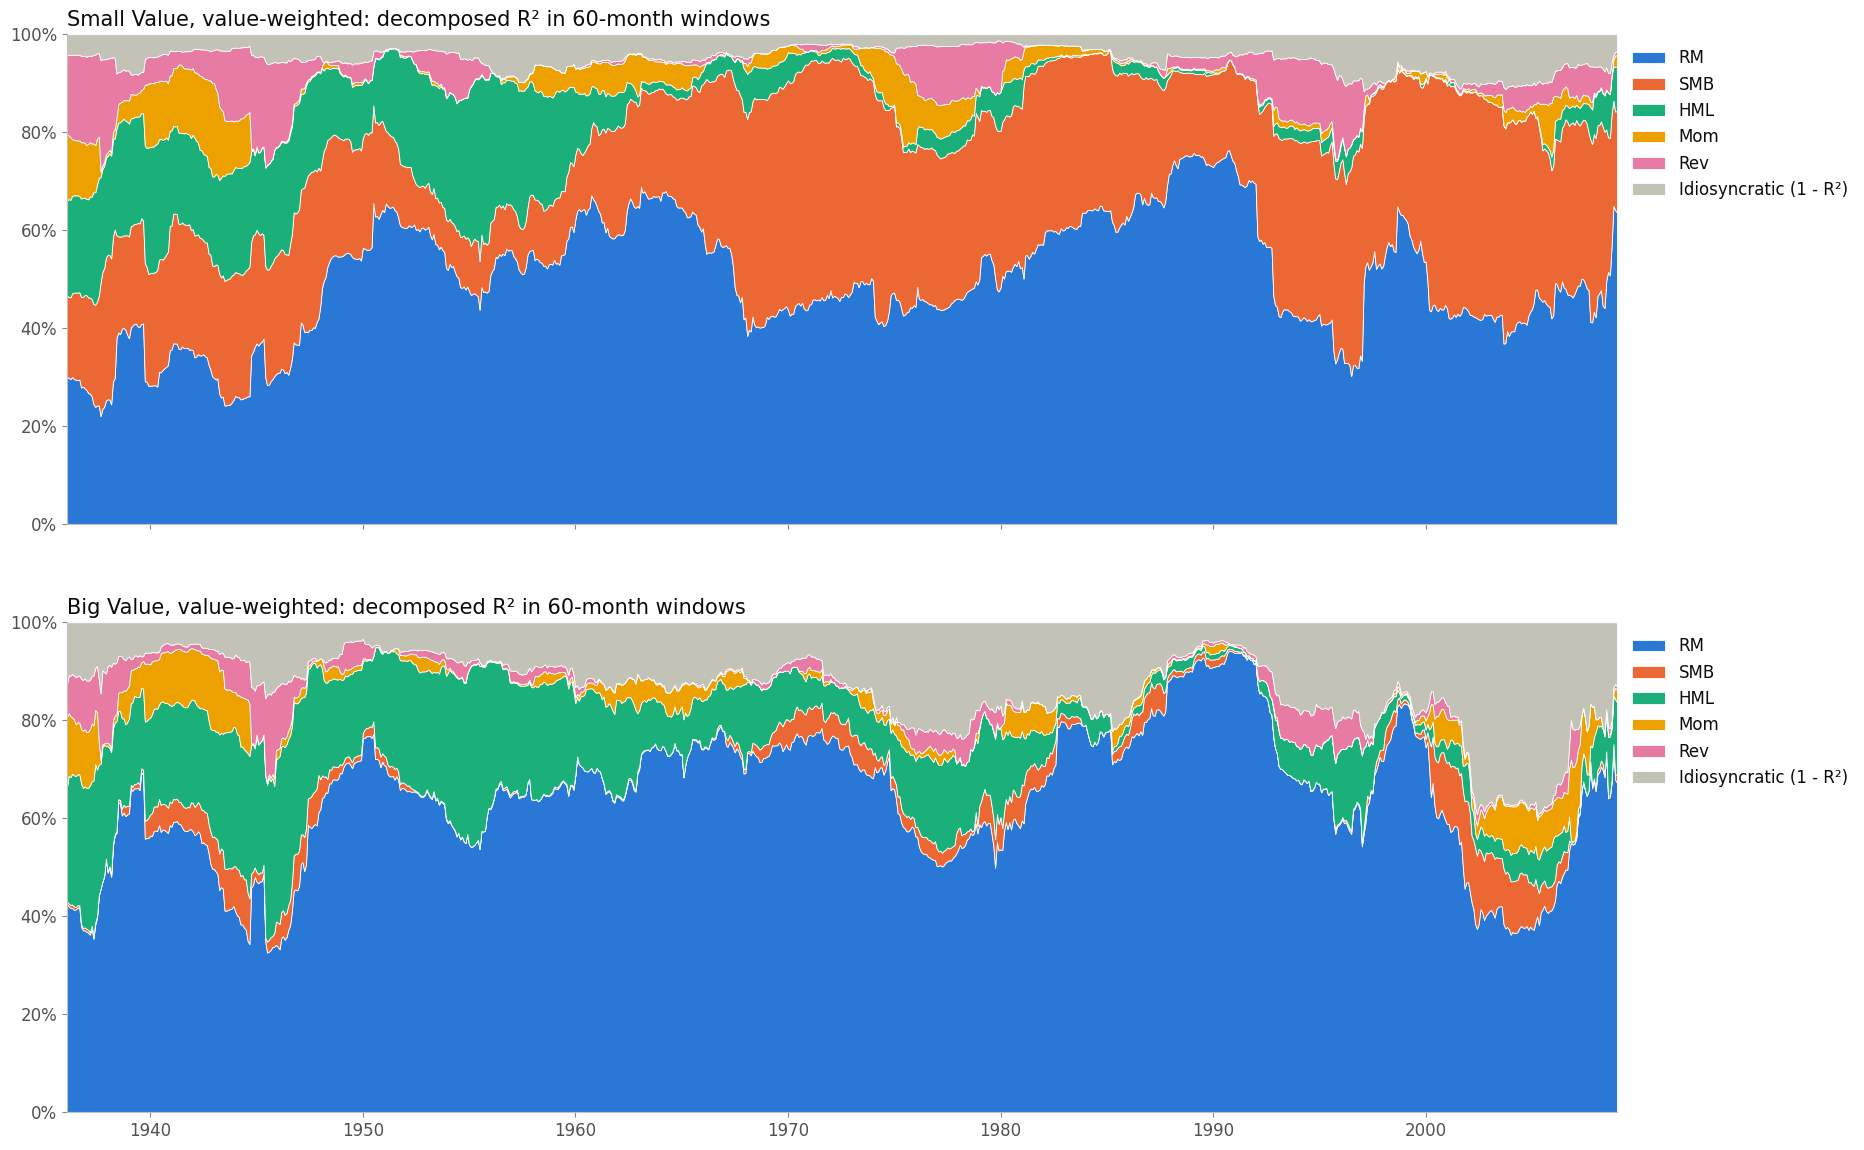

In [21]:
value_portfolios = size_bm_25[['SMALL HiBM', 'BIG HiBM']].rename(columns = {'SMALL HiBM': 'Small Value', 'BIG HiBM': 'Big Value'})
rolling = rolling_window_regression(value_portfolios.loc[sample], F, window_days = 60, orthogonalize = orthogonalize_swl).loc['1936-01':]

fig, axes = plt.subplots(2, 1, figsize = (20, 14), sharex = True)
for ax, name in zip(axes, value_portfolios.columns):
    plot_decomposition(ax, rolling[name], paper_factors, f'{name}, value-weighted: decomposed R² in 60-month windows')
plt.show()

In [22]:
# Correlations between the components over time that the paper reports
pd.DataFrame({'Paper': [0.77, -0.62, -0.67],
              'This repository': [rolling[('Small Value', 'RM')].corr(rolling[('Big Value', 'RM')]),
                                  rolling[('Small Value', 'Rev')].corr(rolling[('Small Value', 'RM')]),
                                  rolling[('Big Value', 'HML')].corr(rolling[('Big Value', 'RM')])]},
             index = ['DR² RM, Small Value with Big Value', 'DR² Rev with DR² RM, Small Value', 'DR² HML with DR² RM, Big Value']).round(2)

,Paper,This repository
"DR² RM, Small Value with Big Value",0.77,0.75
"DR² Rev with DR² RM, Small Value",-0.62,-0.63
"DR² HML with DR² RM, Big Value",-0.67,-0.55


The market is the largest component of both portfolios most of the time, and its share moves together in Small Value and Big Value (correlation of 0.75, against 0.77 in the paper). Size matters for Small Value and hardly for Big Value. The components also trade off against each other: the share of Rev in Small Value moves against the share of the market (−0.63, against −0.62), and so does the share of HML in Big Value (−0.55, against −0.67).

## After the paper: 2009 to the latest month

The same decomposition of the 18 style portfolios, from January 2009 to the last month of the library.

In [23]:
recent = slice('2009-01', factors.dropna().index[-1])
table6_recent = pd.concat({w: decomposition_table(styles[w], recent) for w in weightings})
pd.concat({'1931–2008': table6.groupby(level = [0, 1]).mean(), f'2009–{factors.dropna().index[-1]:%Y}': table6_recent.groupby(level = [0, 1]).mean()}).round(1)

RM   SMB  HML  Mom  Rev  1 - R²
1931–2008 EW Big    78.2   3.9  4.9  6.7  2.8     3.4
             Small  53.1  24.2  6.1  6.6  5.0     5.0
          VW Big    82.2   0.7  4.3  6.3  3.0     3.4
             Small  62.9  20.1  5.4  5.6  3.8     2.3
2009–2026 EW Big    72.4   6.5  4.3  8.5  3.5     4.7
             Small  53.7  22.6  2.6  8.6  5.2     7.3
          VW Big    79.3   0.8  4.5  6.9  4.6     3.9
             Small  60.2  21.4  5.1  7.1  3.6     2.6

Since 2009 the picture is broadly the same. The market explains less of the equal-weighted large caps (72% against 78%), momentum explains a little more of every group, HML explains less of the equal-weighted small caps (2.6% against 6.1%), and their idiosyncratic share rose from 5.0% to 7.3%.

## Summary

In [24]:
paper_means, means = paper_table6.groupby(level = [0, 1]).mean(), table6.groupby(level = [0, 1]).mean()
summary = pd.DataFrame({
    'Paper': [*paper_table3['Resemblance'], paper_panel_a['SW/L'].min().min(), paper_panel_a['PCA'].min().min(),
              paper_panel_a[('GS', 'second')].min(),
              *paper_means.loc[('EW', 'Small'), ['RM', 'SMB', '1 - R²']],
              *paper_means.loc[('EW', 'Big'), ['RM', 'SMB', '1 - R²']],
              0.77, -0.62, -0.67],
    'This repository': [*table3['Resemblance'], panel_a['SW/L'].min().min(), panel_a['PCA'].min().min(),
                        panel_a[('GS', 'second')].min(),
                        *means.loc[('EW', 'Small'), ['RM', 'SMB', '1 - R²']],
                        *means.loc[('EW', 'Big'), ['RM', 'SMB', '1 - R²']],
                        rolling[('Small Value', 'RM')].corr(rolling[('Big Value', 'RM')]),
                        rolling[('Small Value', 'Rev')].corr(rolling[('Small Value', 'RM')]),
                        rolling[('Big Value', 'HML')].corr(rolling[('Big Value', 'RM')])]},
    index = [f'Resemblance of {f}' for f in paper_factors] +
            ['Lowest pair resemblance, SW/L', 'Lowest pair resemblance, PCA', 'Lowest pair resemblance, GS',
             'Small EW portfolios: DR² RM (%)', 'Small EW portfolios: DR² SMB (%)', 'Small EW portfolios: 1 - R² (%)',
             'Big EW portfolios: DR² RM (%)', 'Big EW portfolios: DR² SMB (%)', 'Big EW portfolios: 1 - R² (%)',
             'Rolling DR² RM, Small with Big Value', 'Rolling DR² Rev with RM, Small Value', 'Rolling DR² HML with RM, Big Value'])

summary.round(2).to_csv('results/paper_replication.csv')
table6.round(4).to_csv('results/paper_table6.csv')
summary.round(2)

,Paper,This repository
Resemblance of RM,0.97,0.97
Resemblance of SMB,0.96,0.96
Resemblance of HML,0.92,0.91
Resemblance of Mom,0.97,0.96
Resemblance of Rev,0.91,0.91
"Lowest pair resemblance, SW/L",0.94,0.94
"Lowest pair resemblance, PCA",0.45,0.43
"Lowest pair resemblance, GS",0.79,0.76
Small EW portfolios: DR² RM (%),53.30,53.09
Small EW portfolios: DR² SMB (%),24.68,24.18
